Simulation of different policies 

In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

rng = np.random.default_rng(42)


In [ ]:
# Network parameters
N_ASSETS = 1000
HORIZON = 20
GAMMA = 1                    # Left this as 1 since accidents are as bad short term and long term?
ANNUAL_BUDGET = 200.0        # total across the network
FAILURE_PENALTY = 5.0        # per asset per year in state 4
N_STATES = 5                 # 0=Very Good ... 4 = Critical

STATES = ["Very Good", "Good", "Fair", "Poor", "Critical"] # Chosen depending on Track Geometry Index (TGI) or other TQI?
ACTIONS = ["do_nothing", "minor", "major"]
ACTION_COST = {"do_nothing": 0.0, "minor": 1.0, "major": 8.0}

INITIAL_DIST = np.array([1.0, 0.0, 0.0, 0.0, 0.0])   # all start Very Good

In [7]:
# Transition matrices. No maintance tends to degrade asset, maintance tends to improve asset.
P_DO_NOTHING = np.array([
    [0.85, 0.15, 0.00, 0.00, 0.00],
    [0.00, 0.80, 0.20, 0.00, 0.00],
    [0.00, 0.00, 0.70, 0.30, 0.00],
    [0.00, 0.00, 0.00, 0.60, 0.40],
    [0.00, 0.00, 0.00, 0.00, 1.00],
])

P_MINOR = np.array([
    [0.95, 0.05, 0.00, 0.00, 0.00],
    [0.10, 0.85, 0.05, 0.00, 0.00],
    [0.00, 0.15, 0.80, 0.05, 0.00],
    [0.00, 0.00, 0.20, 0.75, 0.05],
    [0.00, 0.00, 0.00, 0.25, 0.75],
])

P_MAJOR = np.array([
    [1.00, 0.00, 0.00, 0.00, 0.00],
    [0.30, 0.70, 0.00, 0.00, 0.00],
    [0.10, 0.60, 0.30, 0.00, 0.00],
    [0.00, 0.30, 0.60, 0.10, 0.00],
    [0.00, 0.20, 0.50, 0.30, 0.00],
])

P = {"do_nothing": P_DO_NOTHING, "minor": P_MINOR, "major": P_MAJOR}

# Sanity check: each row sums to 1
for name, m in P.items():
    assert np.allclose(m.sum(axis=1), 1), f"{name} rows do not sum to 1"
print("Transition matrices OK")

Transition matrices OK


In [8]:
def simulate_network(policy_fn, n_assets=N_ASSETS, horizon=HORIZON,
                     budget=ANNUAL_BUDGET, rng=None):
    """Run one Monte Carlo trajectory. Returns per-year histories."""
    if rng is None:
        rng = np.random.default_rng()
    states = rng.choice(N_STATES, size=n_assets, p=INITIAL_DIST) # List of initial states 
    # Lists that record the states 
    hist_critical = np.zeros(horizon + 1, dtype=int)
    hist_spend = np.zeros(horizon)
    hist_penalty = np.zeros(horizon)
    hist_critical[0] = (states == 4).sum()

    for t in range(horizon):
        actions = policy_fn(states, budget)                     # list of action strings
        spend = sum(ACTION_COST[a] for a in actions)
        # advance each asset
        new_states = np.empty_like(states)
        for i, (s, a) in enumerate(zip(states, actions)):
            new_states[i] = rng.choice(N_STATES, p=P[a][s])
        states = new_states
        hist_critical[t + 1] = (states == 4).sum()
        hist_spend[t] = spend
        hist_penalty[t] = FAILURE_PENALTY * (states == 4).sum()

    return {"critical": hist_critical, "spend": hist_spend,
            "penalty": hist_penalty}


def total_discounted_cost(hist, gamma=GAMMA):   # prioritise fixing criticals early
    t = np.arange(len(hist["spend"]))
    return (gamma ** t * (hist["spend"] + hist["penalty"])).sum()

In [3]:
def policy_do_nothing(states, budget):
    return ["do_nothing"] * len(states)

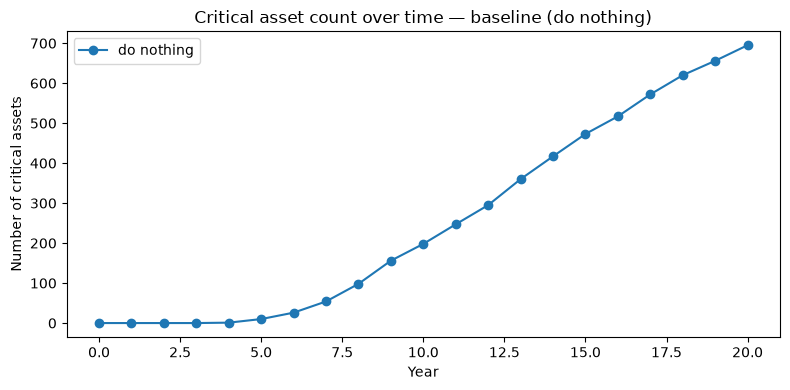

Total discounted cost (do nothing): 12969.1


In [ ]:


run = simulate_network(policy_do_nothing, rng=np.random.default_rng(0))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(run["critical"], marker="o", label="do nothing")
ax.set_xlabel("Year"); ax.set_ylabel("Number of critical assets")
ax.set_title("Critical asset count over time — baseline (do nothing)")
ax.legend(); plt.tight_layout(); plt.show()

print(f"Total discounted cost (do nothing): {total_discounted_cost(run):.1f}")

## Validation against Markov chain theory

For the do-nothing policy, assets evolve as independent homogeneous Markov
chains, so the exact state distribution after $t$ years is

$$
\pi_t = \pi_0 \, P^t,
$$

where:

- $\pi_0$ is the initial state distribution
- $P$ is the do-nothing transition matrix
- $\pi_t$ is the distribution over the 5 states at year $t$

At the 20-year horizon: $\pi_{20} = \pi_0 \, P^{20}$.

Since assets are i.i.d. under this policy, the number of critical assets at
year $t$ is $\text{Binomial}(N, [\pi_t]_4)$, giving an exact mean and variance
to compare against the Monte Carlo simulation.


In [23]:
pi0 = INITIAL_DIST
pi_T = pi0 @ np.linalg.matrix_power(P_DO_NOTHING, HORIZON)
expected_critical_T = N_ASSETS * pi_T[4]

print("Probability distribution of an asset at year 20 is:\n ",pi_T) # The probability distribution of an asset at year 20. 70% chance of being critical!
print("Expected number of critical at year HORIZON:\n ",expected_critical_T)

Probability distribution of an asset at year 20 is:
  [0.03875953 0.08169095 0.08745868 0.08700454 0.7050863 ]
Expected number of critical at year HORIZON:
  705.086302495561


In [12]:
def policy_worst_first(states, budget):
    """Major on worst assets first, then minor, until budget exhausted."""
    actions = ["do_nothing"] * len(states)
    remaining = budget
    order = np.argsort(-states)          # state 4 first, then 3, ...
    for i in order:
        if states[i] == 4 and remaining >= ACTION_COST["major"]:
            actions[i] = "major"; remaining -= ACTION_COST["major"]
        elif states[i] >= 3 and remaining >= ACTION_COST["minor"]:
            actions[i] = "minor"; remaining -= ACTION_COST["minor"]
    return actions


def policy_threshold(k):
    """Minor if state >= k, major if state == 4."""
    def policy(states, budget):
        actions = ["do_nothing"] * len(states)
        remaining = budget
        for i in np.argsort(-states):          # ← worst assets first
            if states[i] == 4 and remaining >= ACTION_COST["major"]:
                actions[i] = "major"; remaining -= ACTION_COST["major"]
            elif states[i] >= k and remaining >= ACTION_COST["minor"]:
                actions[i] = "minor"; remaining -= ACTION_COST["minor"]
        return actions
    return policy

In [13]:
def run_mc(policy_fn, n_reps=10):
    runs = [simulate_network(policy_fn, rng=np.random.default_rng(i))
            for i in range(n_reps)]
    crit = np.array([r["critical"] for r in runs])
    cost = np.array([total_discounted_cost(r) for r in runs])
    return crit, cost

In [14]:


crit_dn, cost_dn = run_mc(policy_do_nothing)
crit_wf, cost_wf = run_mc(policy_worst_first)
print(f"do-nothing total cost: {cost_dn.mean():.1f} ± {cost_dn.std():.1f}")
print(f"worst-first total cost: {cost_wf.mean():.1f} ± {cost_wf.std():.1f}")

do-nothing total cost: 27451.0 ± 763.4
worst-first total cost: 20775.3 ± 1018.0


We get:

- do-nothing total cost: 27451.0 ± 763.4
- worst-first total cost: 20775.3 ± 1018.0

The do-nothing policy spends nothing, yet incurs a much higher total cost. This is expected: critical assets generate failure penalties every year, and in practice those penalties correspond to real losses: compensation to train operators, delay costs, emergency repair, and accident risk.

The magnitude of the penalty is calibrated against those compensation and risk figures, which depend on both the cost of disruption and the probability of an accident while an asset is critical. I would argue for reducing accident probability as far as the budget allows. Where the budget does not allow it, something need to change. For example the traffic frequency or axle load, which would in turn change the transition matrices themselves. It would be interesting to get more accurate data on how the transition matrices change with those actions, then the transition matrices would depend on variables like axe load, speed, frequency, etc. I assume this is predicted with a multivariate linear regression.

In [15]:
K_VALUES = [2, 3, 4]          # k=1 is effectively "maintain everything"; add if curious
N_REPS_SWEEP = 10

sweep = {}
print(f"{'k':>3}  {'crit @ yr20':>12}  {'total cost':>18}  {'spend':>10}")
print("-" * 50)

for k in K_VALUES:
    pol = policy_threshold(k)
    crit, cost = run_mc(pol, n_reps=N_REPS_SWEEP)

    # also get spend, for the budget-utilisation check
    spend = np.mean([
        simulate_network(pol, rng=np.random.default_rng(i))["spend"].sum()
        for i in range(N_REPS_SWEEP)
    ])

    sweep[k] = cost.mean()
    print(f"{k:>3}  {crit[:, -1].mean():>12.1f}  "
          f"{cost.mean():>10.0f} ± {cost.std():>6.0f}  {spend:>10.0f}")

K_BEST = min(sweep, key=sweep.get)
print(f"\nBest threshold by mean total cost: k = {K_BEST}")

  k   crit @ yr20          total cost       spend
--------------------------------------------------
  2         528.0       16511 ±   1138        3210
  3         564.3       20775 ±   1018        2767
  4         562.1       22878 ±    771        2849

Best threshold by mean total cost: k = 2


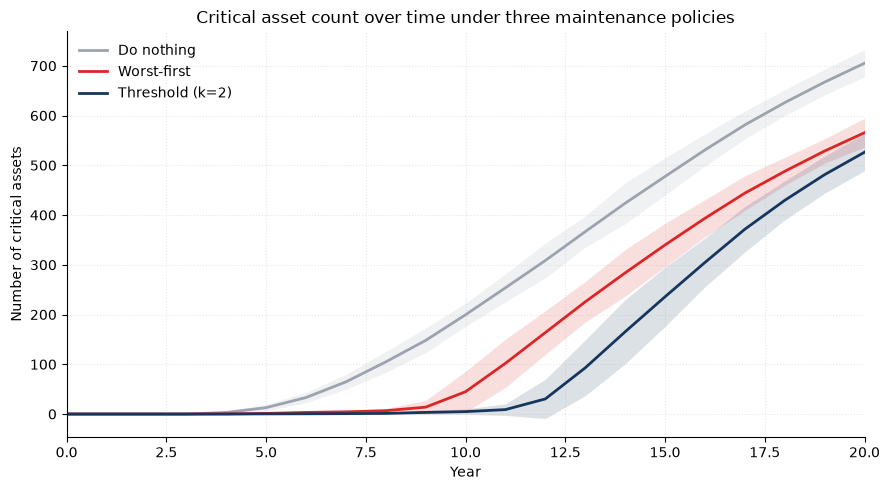

In [18]:
import numpy as np
import matplotlib.pyplot as plt

N_REPS = 20          
K_BEST = 2           

# Monte Carlo for each policy 
crit_dn, cost_dn = run_mc(policy_do_nothing,  n_reps=N_REPS)
crit_wf, cost_wf = run_mc(policy_worst_first, n_reps=N_REPS)
crit_th, cost_th = run_mc(policy_threshold(K_BEST), n_reps=N_REPS)

years = np.arange(crit_dn.shape[1])

def band(arr, z=1.96):
    mean = arr.mean(axis=0)
    sd   = arr.std(axis=0, ddof=1)
    return mean, mean - z*sd, mean + z*sd

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 5))

policies = [
    (crit_dn, "Do nothing",           "#9CA3AF"),
    (crit_wf, "Worst-first",          "#DC2626"),
    (crit_th, f"Threshold (k={K_BEST})", "#17365D"),
]

for arr, label, color in policies:
    mean, lo, hi = band(arr)
    ax.plot(years, mean, label=label, color=color, linewidth=2)
    ax.fill_between(years, lo, hi, color=color, alpha=0.15, linewidth=0)

ax.set_xlabel("Year")
ax.set_ylabel("Number of critical assets")
ax.set_title("Critical asset count over time under three maintenance policies")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.3, linestyle=":")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, years[-1])

plt.tight_layout()
plt.savefig("../figures/critical_comparison.png", dpi=150, bbox_inches="tight")
plt.show()